# 01. 단층 퍼셉트론(Perceptron) & ADALINE

## 🎯 이 노트북에서 배울 것
1. **퍼셉트론**의 구조와 학습 규칙, 그리고 결정 경계를 직접 그려보기
2. 퍼셉트론이 **풀 수 없는 문제(XOR)** — 선형 분리 불가
3. **ADALINE**: 선형 출력 + MSE 손실 + 경사하강법 ( 요즘 딥러닝의 grandfather )

## 📖 핵심 개념
- 퍼셉트론(Rosenblatt, 1958): 입력 `x` → 가중합 `z = w·x + b` → **계단 함수**로 출력 0/1 결정
- 학습 규칙: `w ← w + η·(정답 − 예측)·x` (틀린 샘플에 대해서만 가중치 갱신)
- ADALINE(Widrow & Hoff, 1960): 계단 함수 **적용 전에** 선형 출력으로 오차를 계산하고 MSE를 **경사하강법**으로 최소화 → 미분 가능해져서 이후 딥러닝의 토대가 됨


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
# 한글 라벨이 깨지지 않도록,환경에 설치된 한글/CJK 폰트를 자동으로 찾아 설정
# (Windows: Malgun Gothic, macOS: AppleGothic, 리눅스: Noto Sans CJK KR 등)
_cjk_fonts = ["Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR",
              "NanumGothic", "WenQuanYi Zen Hei", "DejaVu Sans"]
_installed = {f.name for f in fm.fontManager.ttflist}
for _name in _cjk_fonts:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break

# 매번 실행해도 같은 결과가 나오도록 시드 고정 (학습 결과를 비교하기 위함)
np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 5)


## 1) 단층 퍼셉트론으로 AND 게이트 학습하기

AND는 입력 (0,0), (0,1), (1,0) → 출력 -1, (1,1) → 출력 +1 인데,
이 두 그룹은 **직선 하나로 나눌 수 있는**("선형 분리 가능") 문제라 퍼셉트론이 해결할 수 있습니다.

클래스 레이블을 0/1 대신 **-1/+1**로 쓰는 이유: 퍼셉트론 학습 규칙 수식이 -1/+1에서 깔끔하게 표현되기 때문입니다.


In [2]:
# AND 게이트 진리표
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)  # 입력 (x1, x2)
y = np.array([-1, -1, -1, 1])                               # 정답 레이블 (-1 또는 +1)

class Perceptron:
    """단층 퍼셉트론: 가중합 + 계단 함수"""
    def __init__(self, n_features, lr=0.1, epochs=20):
        # 가중치 w를 0이 아닌 '작은 난수'로 초기화하는 이유:
        # 완전히 0으로 시작하면 모든 입력에 출력이 똑같아져 학습이 진행되지 않을 수 있음
        self.w = np.random.randn(n_features) * 0.01
        self.b = 0.0          # 편향(bias): 결정 경계(직선)를 원점에서 원하는 위치로 이동시키는 역할
        self.lr = lr          # 학습률(learning rate): 한 번에 가중치를 얼마나 바꿀지 (너무 크면 발산, 작으면 느림)
        self.epochs = epochs  # 전체 데이터를 몇 번 반복해서 볼지
        self.errors_ = []     # 에포크별 '틀린 샘플 수' 기록 → 학습이 잘 되는지 눈으로 확인용

    def net_input(self, X):
        # 가중합 z = w1*x1 + w2*x2 + ... + b  (선형 결합, 벡터화: X @ w)
        return X @ self.w + self.b

    def predict(self, X):
        # 계단 함수(step function): z >= 0 → +1, 아니면 -1
        # '활성화 함수가 계단 함수'라는 점이 퍼셉트론의 핵심 특징
        return np.where(self.net_input(X) >= 0.0, 1, -1)

    def fit(self, X, y):
        for epoch in range(self.epochs):
            errors = 0
            # 샘플을 하나씩 순회하며 갱신하는 방식 = '온라인 학습'
            for xi, target in zip(X, y):
                # ★ 퍼셉트론 학습 규칙:  w ← w + η * (정답 - 예측) * x
                # 예측이 맞으면 (정답-예측)=0 이라 가중치가 변하지 않고, 틀리면 그만큼 보정됨
                update = self.lr * (target - self.predict(xi))
                self.w += update * xi   # 가중치 갱신
                self.b += update        # 편향도 같은 규칙으로 갱신 (x에 1을 곱한 것처럼 취급)
                errors += int(update != 0.0)
            self.errors_.append(errors)
            if errors == 0:
                # 모든 샘플을 맞혔으면 더 이상 학습할 필요가 없으므로 조기 종료
                print(f"에포크 {epoch + 1}에서 완벽하게 분리되었습니다!")
                break
        return self


In [3]:
model = Perceptron(n_features=2, lr=0.1, epochs=20)
model.fit(X, y)

print("학습된 가중치 w =", np.round(model.w, 3), "  편향 b =", round(model.b, 3))
print("입력:", X)
print("예측:", model.predict(X), "  정답:", y)
print("정확도:", (model.predict(X) == y).mean())


에포크 4에서 완벽하게 분리되었습니다!
학습된 가중치 w = [0.205 0.199]   편향 b = -0.4
입력: [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
예측: [-1 -1 -1  1]   정답: [-1 -1 -1  1]
정확도: 1.0


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54140 (\N{HANGUL SYLLABLE PEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49481 (\N{HANGUL SYLLABLE SEB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 53944 (\N{HANGUL SYLLABLE TEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 47200 (\N{HANGUL SYLLABLE RON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51004 (\N{HANGUL SYLLABLE EU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

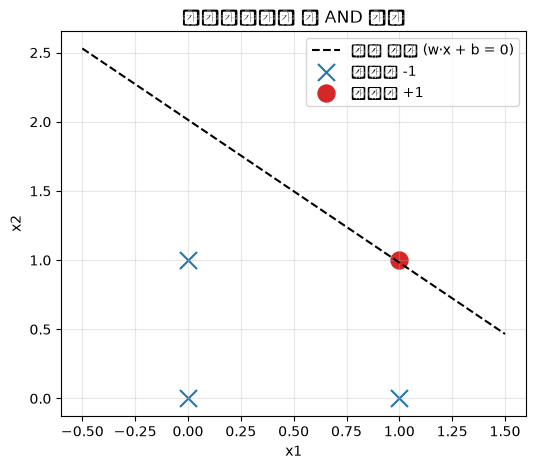

In [4]:
def plot_decision_boundary(model, X, y, title):
    # 결정 경계는 w1*x1 + w2*x2 + b = 0 인 직선 → x2 = -(w1*x1 + b) / w2 로 그릴 수 있음
    x1 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 100)
    x2 = -(model.w[0] * x1 + model.b) / model.w[1]
    plt.plot(x1, x2, "k--", label="결정 경계 (w·x + b = 0)")
    plt.scatter(X[y == -1, 0], X[y == -1, 1], marker="x", s=150, c="tab:blue", label="클래스 -1")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], marker="o", s=150, c="tab:red", label="클래스 +1")
    plt.xlabel("x1"); plt.ylabel("x2"); plt.title(title)
    plt.legend(); plt.grid(alpha=0.3)

plot_decision_boundary(model, X, y, "퍼셉트론으로 푼 AND 문제")
plt.show()


## 2) 퍼셉트론의 한계: XOR 문제

XOR는 (0,0),(1,1) → -1 과 (0,1),(1,0) → +1 인데, 그림을 그려보면 **직선 하나로 두 그룹을 나눌 수 없습니다**.
이를 '선형 분리 불가(non-linearly separable)'라고 합니다. 아래 코드로 퍼셉트론이 절대 100%를 달성하지 못함을 확인해보세요.

👉 이 한계를 극복하기 위해 **은닉층을 쌓은 MLP**가등장합니다 (다음 노트북 `02_MLP.ipynb`).


XOR 예측: [ 1  1 -1 -1]   정답: [-1  1  1 -1]
XOR 정확도: 0.5


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45208 (\N{HANGUL SYLLABLE NA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 45716 (\N{HANGUL SYLLABLE NEUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

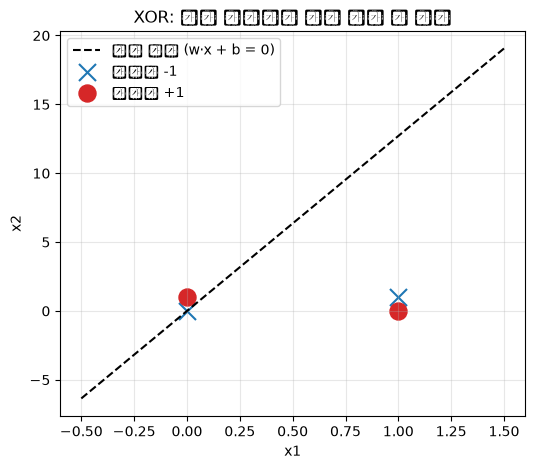

In [5]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([-1, 1, 1, -1])   # XOR 정답

xor_model = Perceptron(n_features=2, lr=0.1, epochs=100)
xor_model.fit(X_xor, y_xor)

print("XOR 예측:", xor_model.predict(X_xor), "  정답:", y_xor)
print("XOR 정확도:", (xor_model.predict(X_xor) == y_xor).mean())
# 정확도가 50% 근처에서 맴돌고 절대 100%가 될 수 없음 = 단층 퍼셉트론의 구조적 한계!

plot_decision_boundary(xor_model, X_xor, y_xor, "XOR: 직선 하나로는 절대 나눌 수 없음")
plt.show()


## 3) ADALINE: 선형 출력 + MSE + 경사하강법

ADALINE은 퍼셉트론과 구조는 같지만 **두 가지**가 다릅니다.

| | 퍼셉트론 | ADALINE |
|---|---|---|
| 오차 계산 | 계단 함수 적용 **후** (0 또는 1) | 선형 출력 z에서 **직접** (실수 오차) |
| 손실/최적화 | 오분류 개수 기반 규칙 | **MSE 손실 + 경사하강법** |
| 의미 | 이산적 갱신 | **연속적이고 미분 가능** → 딥러닝의 출발점 |

학습은 배치 경사하강법: `w ← w + η · Σ(정답 − z)·x` (한 에포크에 전체 데이터의 경사를 합산)


In [6]:
# 2D 이진 분류 데이터: (-2,-2) 주변의 점들과 (2,2) 주변의 점들 (선형 분리 가능)
rng = np.random.default_rng(0)
X_neg = rng.normal(loc=[-2, -2], scale=1.0, size=(60, 2))
X_pos = rng.normal(loc=[2, 2], scale=1.0, size=(60, 2))
X_ada = np.vstack([X_neg, X_pos])
y_ada = np.array([-1] * 60 + [1] * 60)

# ★ 입력 표준화(평균 0, 표준편차 1): 배치 경사하강법의 안정 학습률은 2/λmax(XᵀX)보다 작아야 하는데,
#   표준화하면 λmax가 작아져서 더 큰 학습률로 빠르게 수렴할 수 있음
X_ada = (X_ada - X_ada.mean(axis=0)) / X_ada.std(axis=0)

class AdalineGD:
    """ADALINE: 선형 출력 z = w·x + b 를 MSE로 학습하는 배치 경사하강법"""
    def __init__(self, lr=0.005, epochs=150):
        self.lr = lr
        self.epochs = epochs
        self.cost_ = []   # 에포크별 MSE 손실 기록 (학습 곡선 그릴 때 사용)

    def fit(self, X, y):
        n_features = X.shape[1]
        self.w = np.random.randn(n_features) * 0.01
        self.b = 0.0
        for epoch in range(self.epochs):
            output = X @ self.w + self.b      # ★ 선형 출력 z (계단 함수 적용 전, 실수값!)
            errors = y - output               # 오차 = 정답 - 선형 출력
            # MSE 손실 L = ½ Σ (y - z)² 에 대해 ∂L/∂w = -Σ (y - z)·x 이므로
            # 경사하강법 갱신식은 w ← w + η·Σ (y - z)·x
            self.w += self.lr * X.T @ errors  # X.T @ errors = Σ (y-z)·x (벡터화)
            self.b += self.lr * errors.sum()
            self.cost_.append((errors ** 2).sum() / 2.0)   # 손실 기록
        return self

    def net_input(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        # 예측(분류)할 때만 계단 함수 적용 — 학습은 선형 출력으로, 예측은 0 기준 이진화
        return np.where(self.net_input(X) >= 0.0, 1, -1)


ADALINE 정확도: 0.9916666666666667


/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49552 (\N{HANGUL SYLLABLE SON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49892 (\N{HANGUL SYLLABLE SIL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

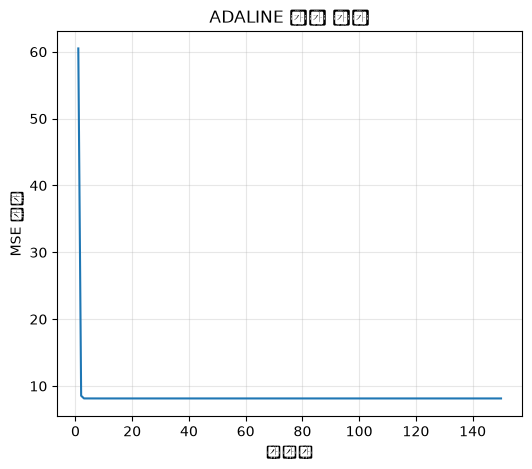

/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 52286 (\N{HANGUL SYLLABLE CAJ}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51008 (\N{HANGUL SYLLABLE EUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 54364 (\N{HANGUL SYLLABLE PYO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 51456 (\N{HANGUL SYLLABLE JUN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/lo

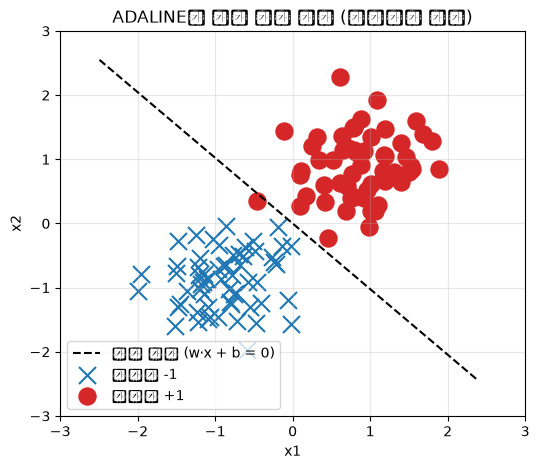

In [7]:
adaline = AdalineGD(lr=0.005, epochs=150)
adaline.fit(X_ada, y_ada)
print("ADALINE 정확도:", (adaline.predict(X_ada) == y_ada).mean())

# 손실이 0에 가깝게 수렴하는지 확인 (경사하강법이 잘 작동했다는 증거)
plt.plot(range(1, len(adaline.cost_) + 1), adaline.cost_)
plt.xlabel("에포크"); plt.ylabel("MSE 손실"); plt.title("ADALINE 학습 곡선")
plt.grid(alpha=0.3); plt.show()

plot_decision_boundary(adaline, X_ada, y_ada, "ADALINE이 찾은 결정 경계 (표준화된 좌표)")
plt.xlim(-3, 3); plt.ylim(-3, 3); plt.show()


## ✅ 정리

- **퍼셉트론**: `z = w·x + b` → 계단 함수, 틀린 샘플만 갱신. 선형 분리 가능한 문제만 해결 (AND는 가능, **XOR는 불가**)
- **ADALINE**: 계단 함수 **전** 선형 출력으로 MSE 오차를 계산 → 경사하강법으로 연속 최적화. 미분 가능성 때문에 현대 딥러닝의 ancestor
- 다음 노트북에서는 은닉층을 쌓아 **XOR을 해결하는 MLP와 역전파**를 numpy로 직접 구현합니다 → [`02_MLP.ipynb`](./02_MLP.ipynb)
